Build and compare machine-learning classifiers for the thyroid classes created from the dataset's original target field.

In [655]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [656]:
df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks (1)/thyroidDF.csv')
df

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,f,f,f,f,f,f,f,f,...,64.0,t,0.83,t,77.0,f,NaN,SVI,-,870119022
9168,22,M,f,f,f,f,f,f,f,f,...,91.0,t,0.92,t,99.0,f,NaN,SVI,-,870119023
9169,69,M,f,f,f,f,f,f,f,f,...,113.0,t,1.27,t,89.0,f,NaN,SVI,I,870119025
9170,47,F,f,f,f,f,f,f,f,f,...,75.0,t,0.85,t,88.0,f,NaN,other,-,870119027


Initial dataset inspection

In [657]:
df.shape

(9172, 31)

In [658]:
df.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047


In [659]:
df.tail()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
9167,56,M,f,f,f,f,f,f,f,f,...,64.0,t,0.83,t,77.0,f,NaN,SVI,-,870119022
9168,22,M,f,f,f,f,f,f,f,f,...,91.0,t,0.92,t,99.0,f,NaN,SVI,-,870119023
9169,69,M,f,f,f,f,f,f,f,f,...,113.0,t,1.27,t,89.0,f,NaN,SVI,I,870119025
9170,47,F,f,f,f,f,f,f,f,f,...,75.0,t,0.85,t,88.0,f,NaN,other,-,870119027
9171,31,M,f,f,f,f,f,f,f,t,...,66.0,t,1.02,t,65.0,f,NaN,other,-,870119035


In [660]:
df.dtypes

,0
age,int64
sex,object
on_thyroxine,object
query_on_thyroxine,object
on_antithyroid_meds,object
sick,object
pregnant,object
thyroid_surgery,object
I131_treatment,object
query_hypothyroid,object


In [661]:
df.duplicated().sum()

np.int64(0)

In [662]:
df['target']

,target
0,-
1,-
2,-
3,-
4,S
...,...
9167,-
9168,-
9169,I
9170,-


In [663]:
p=df['target'].value_counts()
p

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [664]:
df['target'].isnull().sum()

np.int64(0)

<BarContainer object of 32 artists>

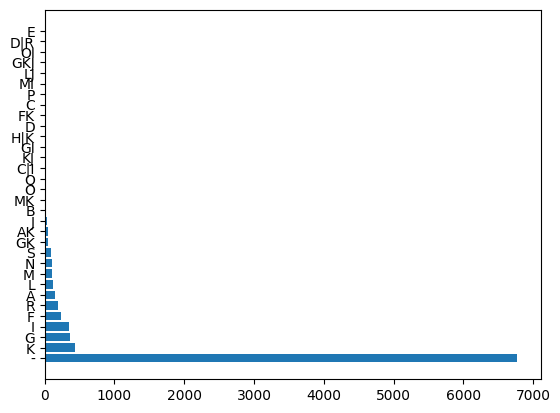

In [665]:
#plot target coloumn
plt.barh(p.index,p.values)

3. Target class preparation

In [666]:
#add new colown rearrange class label

df.loc[df['target'] == '-', 'thyroid_class'] = 'Negative'

# 1. Hyperthyroid
df.loc[df['target'].str[0].isin(['A', 'B', 'C', 'D']),
       'thyroid_class'] = 'Hyperthyroid'

# 2. Hypothyroid
df.loc[df['target'].str[0].isin(['E', 'F', 'G', 'H']),
       'thyroid_class'] = 'Hypothyroid'

# 3. Binding protein
df.loc[df['target'].str[0].isin(['I', 'J']),
       'thyroid_class'] = 'Binding Protein'

# 4. Other conditions
df.loc[~df['target'].str[0].isin(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J','-']),
       'thyroid_class'] = 'Other'

In [667]:
df.isna().sum()

,0
age,0
sex,307
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
I131_treatment,0
query_hypothyroid,0


In [668]:
#drop patient id coloumn drop target coloum and save balance to df1
df1=df.drop(['target'],axis=1)

df1.drop(['patient_id','TBG','TBG_measured'],axis=1,inplace=True)
df1

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,referral_source,thyroid_class
0,29,F,f,f,f,f,f,f,f,t,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
1,29,F,f,f,f,f,f,f,f,f,...,t,1.9,t,128.0,f,NaN,f,NaN,other,Negative
2,41,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
3,36,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
4,32,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,f,f,f,f,f,f,f,f,...,f,NaN,t,64.0,t,0.83,t,77.0,SVI,Negative
9168,22,M,f,f,f,f,f,f,f,f,...,f,NaN,t,91.0,t,0.92,t,99.0,SVI,Negative
9169,69,M,f,f,f,f,f,f,f,f,...,f,NaN,t,113.0,t,1.27,t,89.0,SVI,Binding Protein
9170,47,F,f,f,f,f,f,f,f,f,...,f,NaN,t,75.0,t,0.85,t,88.0,other,Negative


In [669]:
#check duplicat rows leave patiend id is unique if patient id in dataset and calculate duplicte it will return 0
#df1 have no patient id coloumn
df1.duplicated().sum()

np.int64(102)

In [670]:
#drop duplicated coloumns
df1.drop_duplicates(inplace=True)
df1

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,referral_source,thyroid_class
0,29,F,f,f,f,f,f,f,f,t,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
1,29,F,f,f,f,f,f,f,f,f,...,t,1.9,t,128.0,f,NaN,f,NaN,other,Negative
2,41,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
3,36,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
4,32,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,f,f,f,f,f,f,f,f,...,f,NaN,t,64.0,t,0.83,t,77.0,SVI,Negative
9168,22,M,f,f,f,f,f,f,f,f,...,f,NaN,t,91.0,t,0.92,t,99.0,SVI,Negative
9169,69,M,f,f,f,f,f,f,f,f,...,f,NaN,t,113.0,t,1.27,t,89.0,SVI,Binding Protein
9170,47,F,f,f,f,f,f,f,f,f,...,f,NaN,t,75.0,t,0.85,t,88.0,other,Negative


In [671]:
df1.shape

(9070, 28)

In [672]:
#now target coloumn is throid_class count
df1['thyroid_class'].value_counts()

,count
thyroid_class,
Negative,6690
Other,1096
Hypothyroid,667
Binding Protein,376
Hyperthyroid,241


<Axes: xlabel='thyroid_class', ylabel='count'>

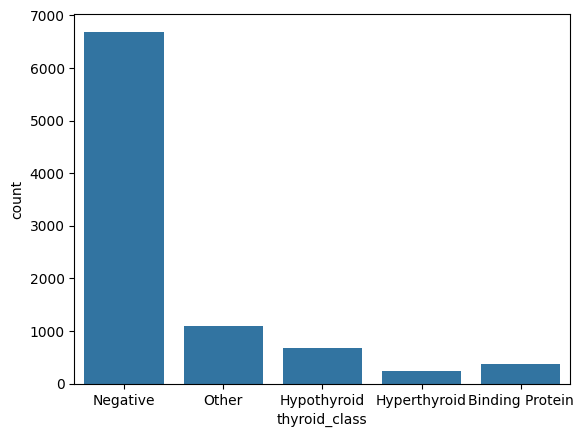

In [673]:
#plot count
sns.countplot(x=df1['thyroid_class'],data=df)

4. Dataset cleaning and exploratory analysis

In [674]:
#drop patient id coloumn drop target coloum and save balance to df1
df1=df.drop(['target'],axis=1)

df1.drop(['patient_id','TBG','TBG_measured'],axis=1,inplace=True)
df1

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,referral_source,thyroid_class
0,29,F,f,f,f,f,f,f,f,t,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
1,29,F,f,f,f,f,f,f,f,f,...,t,1.9,t,128.0,f,NaN,f,NaN,other,Negative
2,41,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
3,36,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
4,32,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,f,f,f,f,f,f,f,f,...,f,NaN,t,64.0,t,0.83,t,77.0,SVI,Negative
9168,22,M,f,f,f,f,f,f,f,f,...,f,NaN,t,91.0,t,0.92,t,99.0,SVI,Negative
9169,69,M,f,f,f,f,f,f,f,f,...,f,NaN,t,113.0,t,1.27,t,89.0,SVI,Binding Protein
9170,47,F,f,f,f,f,f,f,f,f,...,f,NaN,t,75.0,t,0.85,t,88.0,other,Negative


In [675]:
#check duplicat rows leave patiend id is unique if patient id in dataset and calculate duplicte it will return 0
#df1 have no patient id coloumn
df1.duplicated().sum()

np.int64(102)

In [676]:
#drop duplicated coloumns
df1.drop_duplicates(inplace=True)
df1

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,referral_source,thyroid_class
0,29,F,f,f,f,f,f,f,f,t,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
1,29,F,f,f,f,f,f,f,f,f,...,t,1.9,t,128.0,f,NaN,f,NaN,other,Negative
2,41,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
3,36,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Negative
4,32,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,f,f,f,f,f,f,f,f,...,f,NaN,t,64.0,t,0.83,t,77.0,SVI,Negative
9168,22,M,f,f,f,f,f,f,f,f,...,f,NaN,t,91.0,t,0.92,t,99.0,SVI,Negative
9169,69,M,f,f,f,f,f,f,f,f,...,f,NaN,t,113.0,t,1.27,t,89.0,SVI,Binding Protein
9170,47,F,f,f,f,f,f,f,f,f,...,f,NaN,t,75.0,t,0.85,t,88.0,other,Negative


In [677]:
df1.duplicated().sum()

np.int64(0)

In [678]:
#check max min values and numerical coloumn deatils
df1.describe()

,age,TSH,T3,TT4,T4U,FTI
count,9070.000000,8328.000000,6566.000000,8728.000000,8361.000000,8368.000000
mean,73.893164,5.219434,1.970650,108.704017,0.976067,113.643528
std,1190.610752,24.186817,0.887711,37.525337,0.200377,41.553807
min,1.000000,0.005000,0.050000,2.000000,0.170000,1.400000
25%,37.000000,0.460000,1.500000,87.000000,0.860000,93.000000
50%,55.000000,1.400000,1.900000,104.000000,0.960000,109.000000
75%,68.000000,2.700000,2.300000,126.000000,1.070000,128.000000
max,65526.000000,530.000000,18.000000,600.000000,2.330000,881.000000


In [679]:
#age coloumn impossible values detected
df1['age'].unique()

array([   29,    41,    36,    32,    60,    77,    28,    54,    42,
          51,    37,    16,    43,    63,    40,    75,    56,    85,
          71,    67,    55,    61,    46,    44,    82,    64,    70,
          33,    59,    53,    52,    49,    35,    48,    27,    69,
          76,    73,    68,    66,    30,    88,    38,    58,    21,
          45,    83,    62,    25,    86,    72,    14,    15,    39,
          26,    20,    80,    90,    23,    18,    13,    78,    24,
          81,    92,    57,    74,     9,    47,    17,    11,    50,
          34,     8,    79,    31,    65,    84,    12,    10,    19,
          22,     1,     2,    97,     6,    89,    87,   455,    93,
           7,    91,     5,    94,     4, 65511,    95, 65512,     3,
       65526])

In [680]:
#remove impossible ages
median_age=df1['age'].median()
for i in df1.index:
  if df1.loc[i,'age']>98:
    df1.loc[i,'age']=median_age

In [681]:
df1.isna().sum()

,0
age,0
sex,306
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
I131_treatment,0
query_hypothyroid,0


5. Feature and target separation

In [682]:
#feature target split
x = df1.iloc[:, :-1]
x
y=df1.iloc[:,-1]
y

,thyroid_class
0,Negative
1,Negative
2,Negative
3,Negative
4,Other
...,...
9167,Negative
9168,Negative
9169,Binding Protein
9170,Negative


6. Statistical analysis and feature assessment

In [683]:
#chi square test
from scipy.stats import chi2_contingency

# Select all object columns except target
cat_cols = x.select_dtypes(include='object')

for col in cat_cols:
    table = pd.crosstab(x[col],y)

    chi, p, dof, expected = chi2_contingency(table)

    print(col, "Chi-square:", chi, "P-value:", p)

sex Chi-square: 116.73447927162199 P-value: 2.660582673485789e-24
on_thyroxine Chi-square: 485.2124747157849 P-value: 1.0571539675240833e-103
query_on_thyroxine Chi-square: 4.6452468052654705 P-value: 0.32567062855276185
on_antithyroid_meds Chi-square: 9.723647069010037 P-value: 0.04534919760506076
sick Chi-square: 12.322159480589537 P-value: 0.01510969075771883
pregnant Chi-square: 817.7577593559128 P-value: 1.0934887758289816e-175
thyroid_surgery Chi-square: 13.302220579478117 P-value: 0.00988971929442552
I131_treatment Chi-square: 1.2360317550893112 P-value: 0.8721313410996983
query_hypothyroid Chi-square: 88.52410414957083 P-value: 2.7099998457808595e-18
query_hyperthyroid Chi-square: 239.31503834880874 P-value: 1.3030290435322425e-50
lithium Chi-square: 9.119403031421989 P-value: 0.05818328917132777
goitre Chi-square: 12.640769461583213 P-value: 0.013171210614100242
tumor Chi-square: 80.82451074419532 P-value: 1.1649556018746935e-16
hypopituitary Chi-square: 14.554304218894387 P-v

In [684]:
#query_on_thyroxine,#1131 treatment# lithium (0.05818328917132777)
#consider dropping
#lithium not necessarily drop it almost 0.05
x.drop(['query_on_thyroxine','I131_treatment','lithium'],axis=1,inplace=True)

In [685]:
##Assoaiation ANOVA insted of corr
from scipy.stats import f_oneway

num_cols = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
rows = []
for c in num_cols:
    groups = [x.loc[y == k, c].dropna() for k in y.unique()]
    F, p = f_oneway(*groups)
    rows.append({"feature": c, "F": round(F), "p_value": p})

pd.DataFrame(rows).sort_values("F", ascending=False)

,feature,F,p_value
5,FTI,778,0.000000e+00
2,T3,756,0.000000e+00
3,TT4,723,0.000000e+00
1,TSH,520,0.000000e+00
4,T4U,505,0.000000e+00
0,age,54,3.229467e-45


7. Missing-value treatment

In [686]:
#missing value filling in numeric coloumns
lab_cols = ["TSH", "T3", "TT4", "T4U", "FTI"]
print(x[lab_cols].median())
x[lab_cols] = x[lab_cols].fillna(x[lab_cols].median())

TSH      1.40
T3       1.90
TT4    104.00
T4U      0.96
FTI    109.00
dtype: float64


In [687]:

x['sex'].fillna(sexcol_mode, inplace=True)

/tmp/ipykernel_1014/3082888247.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  x['sex'].fillna(sexcol_mode, inplace=True)


In [688]:
x.isna().sum()

,0
age,0
sex,0
on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
query_hypothyroid,0
query_hyperthyroid,0
goitre,0


In [689]:
x['sex'].unique()


array(['F', 'M', np.int64(1)], dtype=object)

8. Categorical feature encoding and transformation

In [690]:
#20 true_false object coloumn convaet t/f 1 or 0(label encode or map)
#20 query /true false coloumn converted to 0 and1
#now object coloumn reduces/
flag_cols = [c for c in x.columns if set(x[c].dropna().unique()) <= {"t", "f"}]
for c in flag_cols:
    x[c] = x[c].map({"t": 1, "f": 0})
x

,age,sex,on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,query_hypothyroid,query_hyperthyroid,goitre,...,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,referral_source
0,29,F,0,0,0,0,0,1,0,0,...,0.3,0,1.9,0,104.0,0,0.96,0,109.0,other
1,29,F,0,0,0,0,0,0,0,0,...,1.6,1,1.9,1,128.0,0,0.96,0,109.0,other
2,41,F,0,0,0,0,0,0,1,0,...,1.4,0,1.9,0,104.0,0,0.96,0,109.0,other
3,36,F,0,0,0,0,0,0,0,0,...,1.4,0,1.9,0,104.0,0,0.96,0,109.0,other
4,32,F,0,0,0,0,0,0,0,0,...,1.4,0,1.9,0,104.0,0,0.96,0,109.0,other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,0,0,0,0,0,0,1,0,...,1.4,0,1.9,1,64.0,1,0.83,1,77.0,SVI
9168,22,M,0,0,0,0,0,0,0,0,...,1.4,0,1.9,1,91.0,1,0.92,1,99.0,SVI
9169,69,M,0,0,0,0,0,0,0,0,...,1.4,0,1.9,1,113.0,1,1.27,1,89.0,SVI
9170,47,F,0,0,0,0,0,0,0,0,...,1.4,0,1.9,1,75.0,1,0.85,1,88.0,other


In [691]:
x['referral_source'].unique()

array(['other', 'SVI', 'SVHC', 'STMW', 'SVHD', 'WEST'], dtype=object)

In [692]:
#encoding?map sex coloumn
x['sex']=x['sex'].map({"F":1,"M":0})

In [693]:
#referral source coloumn
#get dummies encoding Encoding  on referral source

x = pd.get_dummies(x, columns=["referral_source"], drop_first=True, dtype=int)
x

,age,sex,on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,query_hypothyroid,query_hyperthyroid,goitre,...,TT4,T4U_measured,T4U,FTI_measured,FTI,referral_source_SVHC,referral_source_SVHD,referral_source_SVI,referral_source_WEST,referral_source_other
0,29,1.0,0,0,0,0,0,1,0,0,...,104.0,0,0.96,0,109.0,0,0,0,0,1
1,29,1.0,0,0,0,0,0,0,0,0,...,128.0,0,0.96,0,109.0,0,0,0,0,1
2,41,1.0,0,0,0,0,0,0,1,0,...,104.0,0,0.96,0,109.0,0,0,0,0,1
3,36,1.0,0,0,0,0,0,0,0,0,...,104.0,0,0.96,0,109.0,0,0,0,0,1
4,32,1.0,0,0,0,0,0,0,0,0,...,104.0,0,0.96,0,109.0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,0.0,0,0,0,0,0,0,1,0,...,64.0,1,0.83,1,77.0,0,0,1,0,0
9168,22,0.0,0,0,0,0,0,0,0,0,...,91.0,1,0.92,1,99.0,0,0,1,0,0
9169,69,0.0,0,0,0,0,0,0,0,0,...,113.0,1,1.27,1,89.0,0,0,1,0,0
9170,47,1.0,0,0,0,0,0,0,0,0,...,75.0,1,0.85,1,88.0,0,0,0,0,1


In [694]:
#TSH LOG TRANSFORMATION
#TSH has some very large values, so log transformation makes those values smaller and easier for the models to handle.
x["TSH"] = np.log1p(x["TSH"])

9. Train-test split and feature scaling

In [695]:
#train_test_split(stratified) imbalance classes are properly distributed

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42)

print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))    # should match the line above

thyroid_class
Negative           0.738
Other              0.121
Hypothyroid        0.073
Binding Protein    0.041
Hyperthyroid       0.027
Name: proportion, dtype: float64
thyroid_class
Negative           0.738
Other              0.121
Hypothyroid        0.074
Binding Protein    0.041
Hyperthyroid       0.026
Name: proportion, dtype: float64


In [696]:
x.dtypes

,0
age,int64
sex,float64
on_thyroxine,int64
on_antithyroid_meds,int64
sick,int64
pregnant,int64
thyroid_surgery,int64
query_hypothyroid,int64
query_hyperthyroid,int64
goitre,int64


In [697]:
#feature scaling standard scaler
#feature scaling
#only scaling continues numeric coloumn
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
# learn from training only
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

In [698]:
print(x_train)

           age  sex  on_thyroxine  on_antithyroid_meds  sick  pregnant  \
1162 -0.169565  1.0             0                    0     0         0   
3449  0.830775  0.0             0                    0     0         0   
2487 -2.064948  1.0             0                    0     0         0   
8119 -0.432813  0.0             0                    0     0         0   
2505  0.409579  0.0             0                    0     0         0   
...        ...  ...           ...                  ...   ...       ...   
3949  1.199322  1.0             1                    0     0         0   
901   0.146332  0.0             0                    0     0         0   
88   -1.169906  0.0             0                    0     0         0   
1681 -0.906659  1.0             0                    0     0         0   
3632  0.093682  0.0             0                    0     0         0   

      thyroid_surgery  query_hypothyroid  query_hyperthyroid  goitre  ...  \
1162                0             

In [699]:
y.value_counts()

,count
thyroid_class,
Negative,6690
Other,1096
Hypothyroid,667
Binding Protein,376
Hyperthyroid,241


In [700]:
#RandomOverSampling

In [701]:
# #oversampling#RandomOver sampler

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
x_train_os, y_train_os = ros.fit_resample(x_train, y_train)

print("before:", y_train.value_counts().to_dict())
print("after: ", y_train_os.value_counts().to_dict())
print(x_train.shape, "->", x_train_os.shape, "| test:", x_test.shape)

before: {'Negative': 5352, 'Other': 877, 'Hypothyroid': 533, 'Binding Protein': 301, 'Hyperthyroid': 193}
after:  {'Negative': 5352, 'Other': 5352, 'Hypothyroid': 5352, 'Binding Protein': 5352, 'Hyperthyroid': 5352}
(7256, 28) -> (26760, 28) | test: (1814, 28)


11. Model development and evaluation

KNN MODEL

before Sampling

In [702]:
from sklearn.neighbors import KNeighborsClassifier
model1=KNeighborsClassifier(n_neighbors=7)
model1.fit(x_train,y_train)
y_pred1=model1.predict(x_test)

ValueError: Input X contains NaN.
KNeighborsClassifier does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
from sklearn.metrics import accuracy_score,classification_report,precision_score,recall_score,f1_score
score1=accuracy_score(y_test,y_pred1)
score1

After Sampling

In [ ]:
model1_o=KNeighborsClassifier(n_neighbors=7)
model1_o.fit(x_train_os,y_train_os)
y_pred1_o=model1_o.predict(x_test)

In [ ]:
score1_o=accuracy_score(y_test,y_pred1_o)
score1_o

NAIVE BAYES

before sampling

In [ ]:
from sklearn.naive_bayes import GaussianNB
model2=GaussianNB()
model2.fit(x_train,y_train)
y_pred2=model2.predict(x_test)

In [ ]:
score2=accuracy_score(y_test,y_pred2)
score2

After sampling

In [ ]:
from sklearn.naive_bayes import GaussianNB
model2_o=GaussianNB()
model2_o.fit(x_train_os,y_train_os)
y_pred2_o=model2_o.predict(x_test)

In [ ]:
score2_o=accuracy_score(y_test,y_pred2_o)
score2_o

DECISON TREE

before sampling

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model3=DecisionTreeClassifier(criterion='entropy')
model3.fit(x_train,y_train)
y_pred3=model3.predict(x_test)

In [ ]:
score3=accuracy_score(y_test,y_pred3)
score3

after sampling

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model3_o=DecisionTreeClassifier(criterion='entropy')
model3_o.fit(x_train_os,y_train_os)
y_pred3_o=model3_o.predict(x_test)

In [ ]:
score3_o=accuracy_score(y_test,y_pred3_o)
score3_o

12. Training and testing performance comparison

In [ ]:
##interpret overfit
# KNN
print("KNN Training:", model1.score(x_train, y_train))
print("KNN Testing:", model1.score(x_test, y_test))

# Naive Bayes
print("NB Training:", model2.score(x_train, y_train))
print("NB Testing:", model2.score(x_test, y_test))

# Decision Tree
print("DT Training:", model3.score(x_train, y_train))
print("DT Testing:", model3.score(x_test, y_test))

In [ ]:
#Over sampled Models accuracy comparision
graph=pd.DataFrame({"Model":['KNN','NaiveBayes','DecisionTree'],"Score":[score1_o,score2_o,score3_o]})
graph

In [ ]:
sns.barplot(x=graph['Model'],y=graph['Score'],data=graph)

In [ ]:
# THYROCARE AI: MODEL EXPORT CELL
# Paste this as the LAST cell in your original Jupyter notebook and run it
# AFTER all preprocessing, train/test split, scaling, oversampling and model fitting.

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Reconstruct the unencoded patient-input columns from df1.
# df1 contains the original feature values plus the thyroid_class target.
raw_data = df1.drop(columns=["thyroid_class", "patient_id", "TBG", "TBG_measured"],
                    errors="ignore").copy()

# These three variables were removed from x before model training.
raw_data = raw_data.drop(
    columns=["query_on_thyroxine", "I131_treatment", "lithium"],
    errors="ignore"
)

# Defaults and options used to create the patient-details form.
raw_defaults = {}
field_options = {}

for col in raw_data.columns:
    if col == "sex":
        field_options[col] = ["F", "M"]
        mode = raw_data[col].mode(dropna=True)
        raw_defaults[col] = mode.iloc[0] if not mode.empty else "F"
    elif col == "referral_source":
        opts = sorted(raw_data[col].dropna().astype(str).unique().tolist())
        field_options[col] = opts
        mode = raw_data[col].mode(dropna=True)
        raw_defaults[col] = str(mode.iloc[0]) if not mode.empty else (opts[0] if opts else "")
    elif col in flag_cols:
        vals = raw_data[col].dropna().astype(str).str.lower()
        raw_defaults[col] = "t" if (vals == "t").mean() >= 0.5 else "f"
    else:
        vals = pd.to_numeric(raw_data[col], errors="coerce")
        median = vals.median()
        raw_defaults[col] = float(median) if pd.notna(median) else 0.0

# Medians are taken from the same x feature frame used for model training,
# before scaling. x has already had the notebook's missing-value imputation.
lab_cols = ["TSH", "T3", "TT4", "T4U", "FTI"]
lab_medians = {
    c: float(pd.to_numeric(x[c], errors="coerce").median())
    for c in lab_cols if c in x.columns
}
sex_mode = x["sex"].mode(dropna=True).iloc[0] if "sex" in x.columns else 1

# Exact model feature order and numeric columns scaled in the notebook.
feature_columns = list(x_train.columns)
numeric_scale_columns = [c for c in num_cols if c in feature_columns]

# Three original models and their random-oversampling counterparts.
models_for_app = {
    "KNN": model1,
    "Gaussian Naive Bayes": model2,
    "Decision Tree": model3,
    "KNN (oversampled)": model1_o,
    "Gaussian Naive Bayes (oversampled)": model2_o,
    "Decision Tree (oversampled)": model3_o,
}

# Store metrics generated from the held-out test set.
metrics_for_app = {}
predictions_for_app = {
    "KNN": model1.predict(x_test),
    "Gaussian Naive Bayes": model2.predict(x_test),
    "Decision Tree": model3.predict(x_test),
    "KNN (oversampled)": model1_o.predict(x_test),
    "Gaussian Naive Bayes (oversampled)": model2_o.predict(x_test),
    "Decision Tree (oversampled)": model3_o.predict(x_test),
}
training_scores = {
    "KNN": model1.score(x_train, y_train),
    "Gaussian Naive Bayes": model2.score(x_train, y_train),
    "Decision Tree": model3.score(x_train, y_train),
    "KNN (oversampled)": model1_o.score(x_train_os, y_train_os),
    "Gaussian Naive Bayes (oversampled)": model2_o.score(x_train_os, y_train_os),
    "Decision Tree (oversampled)": model3_o.score(x_train_os, y_train_os),
}

class_order = list(pd.Series(y).dropna().unique())

for model_name, pred in predictions_for_app.items():
    metrics_for_app[model_name] = {
        "test_accuracy": float(accuracy_score(y_test, pred)),
        "train_accuracy": float(training_scores[model_name]),
        "classification_report": classification_report(
            y_test, pred, output_dict=True, zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_test, pred, labels=class_order
        ).tolist(),
    }

bundle = {
    "models": models_for_app,
    "class_names": class_order,
    "metrics": metrics_for_app,
    "dataset": df1.copy(),
    "raw_defaults": raw_defaults,
    "field_options": field_options,
    "flag_cols": list(flag_cols),
    "lab_medians": lab_medians,
    "sex_mode": sex_mode,
    "num_cols": numeric_scale_columns,
    "feature_columns": feature_columns,
    "scaler": scaler,
    "referral_categories": field_options.get("referral_source", []),
}

joblib.dump(bundle, "thyroid_model_bundle.joblib")
print("Model bundle saved successfully: thyroid_model_bundle.joblib")
print("Raw form fields:", list(raw_defaults.keys()))
print("Model input columns:", feature_columns)
print("Saved models:", list(models_for_app.keys()))
